# SPREAD LOCATOR: A STATISTICAL DISTRIBUTION ANALYSIS MODEL

# PART 1 – THEORETICAL FOUNDATION

## 1. What is Statistical Distribution?

A statistical distribution describes how data values are spread and how frequently or how likely different values occur.

It helps us understand the centre, spread and shape of data.

**Main characteristics:**

- **Mean:** Average value of the data.
- **Median:** Middle value of the data.
- **Variance:** Measures the spread of data.
- **Standard Deviation:** Measures how far values are spread from the mean.
- **Skewness:** Measures the asymmetry of data.

**Example:** In an e-commerce business, many customers may make small purchases while a few customers make large purchases. Statistical distribution helps us understand this pattern.

## 2. What is a Q-Q Plot and Why is it Used?

A Q-Q Plot (Quantile-Quantile Plot) is a graphical method used to compare sample data with a theoretical distribution, usually a normal distribution.

**Uses:**

- To check whether data follows a normal distribution.
- To identify skewness.
- To detect unusual values.
- To compare two distributions.

**Interpretation:** If the points lie close to a straight line, the data approximately follows the theoretical distribution. If points move away from the line, the data may not be normally distributed.


## 3. Difference Between Discrete and Continuous Distributions

| Discrete Distribution | Continuous Distribution |
|---|---|
| Takes countable values. | Takes values over an interval. |
| Usually represents counts. | Usually represents measurements. |
| Example: Number of transactions per day. | Example: Transaction amount. |
| Uses PMF. | Uses PDF. |

**In this project:** Daily transaction counts are discrete, whereas transaction amounts are treated as continuous.


## 4. What is Bernoulli Distribution?

Bernoulli distribution is a discrete probability distribution with only two possible outcomes: Success (1) and Failure (0).

**Formula:**

P(X = 1) = p

P(X = 0) = 1 − p

Where:

- p = Probability of success.
- 1 − p = Probability of failure.

**Example:** A transaction can either be successful or failed.


## 5. What is Binomial Distribution?

Binomial distribution represents the number of successes in a fixed number of independent trials, where each trial has two possible outcomes.

**Formula:**

P(X = k) = C(n,k) × pᵏ × (1 − p)ⁿ⁻ᵏ

Where:

- n = Number of trials.
- k = Number of successes.
- p = Probability of success.

**Example:** Counting the number of successful transactions in a fixed number of attempts.

## 6. Explain Log-Normal Distribution

A Log-Normal distribution is a continuous probability distribution in which the logarithm of the variable follows a normal distribution.

**Characteristics:**

- Values are always positive.
- The distribution is generally right-skewed.
- It can contain many small values and a few very large values.

**Example:** E-commerce transaction amounts, income and product prices.


## 7. Explain Power Law Distribution

Power Law distribution describes data in which small values occur frequently, while very large values occur less frequently.

**Examples:**

- Website traffic.
- Wealth distribution.
- Product popularity.
- Large transaction amounts.

**Example:** A small number of customers may make very large purchases, while most customers make smaller purchases.


## 8. What is Box-Cox Transformation?

Box-Cox transformation is a statistical technique used to reduce skewness and make data more normally distributed.

**Formula:**

For λ ≠ 0:

y(λ) = (yᵖ − 1) / λ

For λ = 0:

y(λ) = ln(y)

**Uses:**

- Reduces skewness.
- Helps stabilize variance.
- Makes data closer to a normal distribution.

**Note:** Box-Cox transformation requires positive data values.

## 9. Explain Poisson Distribution with an Example

Poisson distribution is a discrete probability distribution used to calculate the probability of a certain number of events occurring in a fixed interval of time or space.

**Formula:**

P(X = k) = (e⁻λ × λᵏ) / k!

Where:

- λ = Average number of events.
- k = Number of events.
- e = Mathematical constant.

**Example:** Number of transactions received by an e-commerce platform in one day.


## 10. What is Z-score Probability?

A Z-score measures how many standard deviations a value is away from the mean.

**Formula:**

Z = (X − μ) / σ

Where:

- X = Observed value.
- μ = Mean.
- σ = Standard deviation.

**Example:** We can calculate how far a ₹5,000 transaction amount is from the average transaction amount.


## 11. Differentiate Probability Density Function (PDF) and Cumulative Distribution Function (CDF)

| PDF | CDF |
|---|---|
| PDF means Probability Density Function. | CDF means Cumulative Distribution Function. |
| Describes probability density. | Gives cumulative probability up to a value. |
| Area over an interval gives probability. | Value ranges from 0 to 1. |
| Used for continuous distributions. | Used for both discrete and continuous distributions. |

**Example:** PDF describes the density around a transaction amount, while CDF gives the probability that a transaction amount is less than or equal to a particular value.



# CONCLUSION

In this theoretical section, we studied statistical distributions and their applications in data analysis. We understood Bernoulli, Binomial, Poisson, Log-Normal and Power Law distributions, along with Q-Q Plot, Box-Cox transformation, Z-score, PDF and CDF.

These concepts help us understand transaction behaviour, data spread, probability and patterns in e-commerce transactions.

## PART 2 – DATA ANALYSIS AND TESTING

## Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import (
    bernoulli, binom, poisson,
    lognorm, pareto, boxcox,
    skew, norm, shapiro
)

import statsmodels.api as sm


## Load Excel dataset

In [2]:
df = pd.read_excel(r"C:\Users\DDR\Downloads\spread_locator_dataset.xlsx")

## Display dataset

In [3]:
display(df.head())

,transaction_id,customer_id,transaction_amount,transaction_date,transaction_count,region,transaction_status
0,e98aa092-3770-4fdb-9502-5b5a6a244811,CUST2824,3821.34,2023-01-26,3,North,Fail
1,11ba6918-dba0-41e5-96cf-f5a7b95f0103,CUST1409,2781.84,2023-01-28,0,East,Fail
2,82b7654b-6eb7-4579-89a0-1a9edec0a7bb,CUST5506,4120.97,2023-01-28,0,South,Fail
3,f7166574-f400-4d53-b526-0b11f6619ddf,CUST5012,6383.78,2023-01-18,2,South,Success
4,8632fe26-b507-4068-9c68-1b2fa04fecb3,CUST4657,2651.61,2023-01-04,4,North,Success


## Dataset information

In [5]:
print("\nDataset Information:")
df.info()

print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())


Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 220 entries, 0 to 219
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   transaction_id      220 non-null    str           
 1   customer_id         220 non-null    str           
 2   transaction_amount  220 non-null    float64       
 3   transaction_date    220 non-null    datetime64[us]
 4   transaction_count   220 non-null    int64         
 5   region              220 non-null    str           
 6   transaction_status  220 non-null    str           
dtypes: datetime64[us](1), float64(1), int64(1), str(4)
memory usage: 23.7 KB
Dataset Shape: (220, 7)

Column Names:
Index(['transaction_id', 'customer_id', 'transaction_amount',
       'transaction_date', 'transaction_count', 'region',
       'transaction_status'],
      dtype='str')

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 220 entries, 0 to 219
Data columns

### Observation

- Total Records: 220
- Total Columns: 7
- Missing Values: 0

### Result

The dataset was successfully loaded and checked. It contains 220 records and 7 columns with no missing values.

## Practical 1: Fit the Data to Bernoulli and Binomial Distributions

### Aim

To fit the transaction data to Bernoulli and Binomial distributions.

### Explanation

Bernoulli distribution is used for two possible outcomes: Success and Failure.

In this dataset, the `transaction_status` column represents whether a transaction was successful or failed.

Binomial distribution is used to estimate the number of successes in a fixed number of trials.

In this project, we use transaction status for Bernoulli distribution and transaction count for an exploratory Binomial approximation.

Total Transactions: 220
Successful Transactions: 98
Failed Transactions: 122
Success Probability: 0.44545454545454544
Failure Probability: 0.5545454545454546


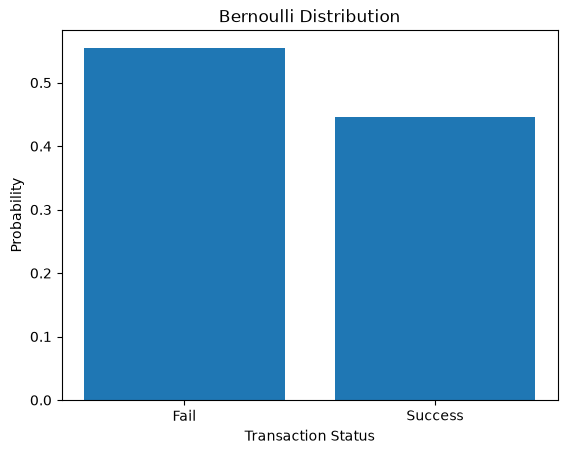

Approximate Number of Trials: 9
Estimated Probability: 0.31717171717171716


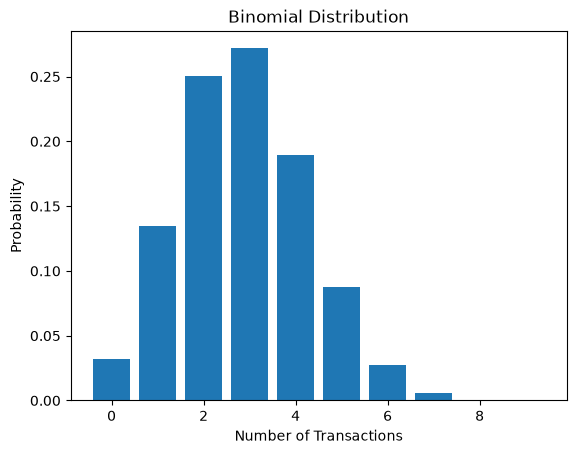

In [6]:
# Bernoulli Distribution

status = df["transaction_status"].astype(str).str.strip().str.lower()

success = (status == "success").astype(int)

p = success.mean()

print("Total Transactions:", len(success))
print("Successful Transactions:", success.sum())
print("Failed Transactions:", len(success) - success.sum())

print("Success Probability:", p)
print("Failure Probability:", 1 - p)

# Plot Bernoulli Distribution

x = [0, 1]
prob = bernoulli.pmf(x, p)

plt.bar(x, prob)
plt.xticks([0, 1], ["Fail", "Success"])
plt.xlabel("Transaction Status")
plt.ylabel("Probability")
plt.title("Bernoulli Distribution")
plt.show()


# Binomial Distribution (Approximation)

counts = df["transaction_count"].dropna()

n = int(counts.max())
p_binom = counts.mean() / n

k = np.arange(n + 1)
binom_prob = binom.pmf(k, n, p_binom)

print("Approximate Number of Trials:", n)
print("Estimated Probability:", p_binom)

plt.bar(k, binom_prob)
plt.xlabel("Number of Transactions")
plt.ylabel("Probability")
plt.title("Binomial Distribution")
plt.show()

### Observation

- Total Transactions: 220
- Successful Transactions: 98
- Failed Transactions: 122
- Success Probability: 0.4455 (44.55%)
- Failure Probability: 0.5545 (55.45%)

**Binomial Distribution:**
- Approximate Number of Trials (n): 9
- Estimated Probability (p): 0.3172

The Bernoulli distribution shows the probability of successful and failed transactions. The Binomial distribution provides an approximate model of transaction counts.

### Result

Bernoulli and Binomial distributions were fitted to the dataset. The success probability was approximately 44.55%, while the failure probability was approximately 55.45%.

The Binomial model is an exploratory approximation because the dataset does not provide complete fixed-trial information for each customer-week.

## Practical 2: Fit the Data to Poisson Distribution

### Aim

To fit the dataset to a Poisson distribution by analyzing the number of transactions per day.

### Explanation

Poisson distribution is used to calculate the probability of a certain number of events occurring in a fixed interval of time.

In this project, Poisson distribution is used to analyze the number of transactions received by the e-commerce platform each day.

The average daily transaction count is represented by lambda (λ).

Number of Days: 31
Average Daily Transactions: 7.096774193548387


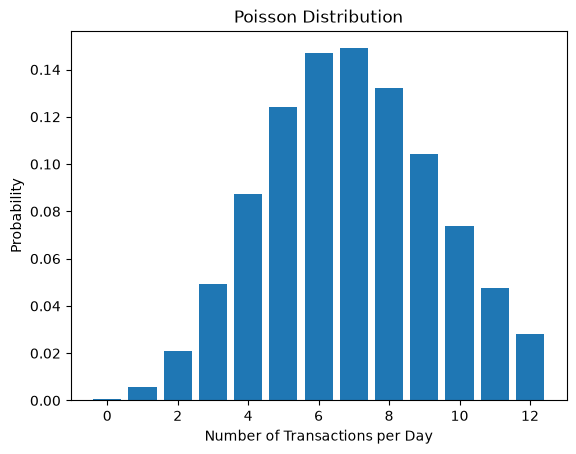

In [7]:
# Convert transaction date into datetime format
df["transaction_date"] = pd.to_datetime(
    df["transaction_date"]
)

# Count transactions per day
daily_counts = df.groupby(
    "transaction_date"
).size()

# Calculate average daily transactions
lam = daily_counts.mean()

print("Number of Days:", len(daily_counts))
print("Average Daily Transactions:", lam)

# Fit Poisson Distribution
x = np.arange(
    0,
    int(daily_counts.max()) + 1
)

prob = poisson.pmf(x, lam)

# Plot Poisson Distribution
plt.bar(x, prob)

plt.xlabel("Number of Transactions per Day")
plt.ylabel("Probability")
plt.title("Poisson Distribution")

plt.show()

### Observation

- Total Number of Days: 31
- Average Daily Transactions (λ): 7.0968
- Daily transaction counts were analyzed using the Poisson distribution.
- The average number of transactions per day is approximately 7.

### Result

The Poisson distribution was successfully fitted to the daily transaction counts. The average daily transaction rate was approximately 7.10 transactions.

This model helps understand the probability of different numbers of transactions occurring in a single day.

## Practical 3: Model Transaction Amounts Using Log-Normal and Power Law Distributions

### Aim

To model the transaction amounts using Log-Normal and Power Law (Pareto) distributions.

### Explanation

Log-Normal distribution is used for positive data where values are generally right-skewed.

Power Law distribution describes data in which smaller values occur frequently, while very large values occur less frequently.

In this project, both distributions are fitted to the `transaction_amount` column of the e-commerce dataset.

The models are compared using Akaike Information Criterion (AIC). A lower AIC indicates a better fit among the fitted models.

Log-Normal AIC: 3821.027805464873
Pareto AIC: 4083.3437741043394


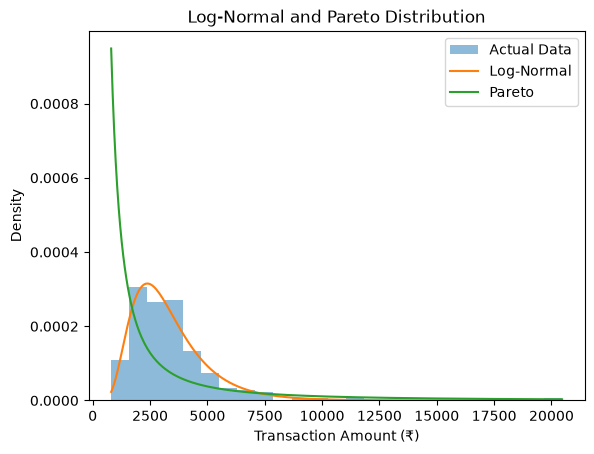

In [9]:
# Select transaction amounts
amounts = df["transaction_amount"].dropna()

# Fit Log-Normal Distribution
shape, loc, scale = lognorm.fit(
    amounts,
    floc=0
)

# Fit Pareto Distribution
b, loc_p, scale_p = pareto.fit(
    amounts,
    floc=0
)

# Calculate Log Likelihood
ll_lognorm = np.sum(
    lognorm.logpdf(
        amounts,
        shape,
        loc=loc,
        scale=scale
    )
)

ll_pareto = np.sum(
    pareto.logpdf(
        amounts,
        b,
        loc=loc_p,
        scale=scale_p
    )
)

# Calculate AIC
aic_lognorm = 4 - 2 * ll_lognorm
aic_pareto = 4 - 2 * ll_pareto

print("Log-Normal AIC:", aic_lognorm)
print("Pareto AIC:", aic_pareto)

# Generate values for plotting
x = np.linspace(
    amounts.min(),
    amounts.max(),
    300
)

# Plot distributions
plt.hist(
    amounts,
    bins=25,
    density=True,
    alpha=0.5,
    label="Actual Data"
)

plt.plot(
    x,
    lognorm.pdf(x, shape, loc=loc, scale=scale),
    label="Log-Normal"
)

plt.plot(
    x,
    pareto.pdf(x, b, loc=loc_p, scale=scale_p),
    label="Pareto"
)

plt.xlabel("Transaction Amount (₹)")
plt.ylabel("Density")
plt.title("Log-Normal and Pareto Distribution")
plt.legend()
plt.show()

### Observation

- Log-Normal AIC: 3821.03
- Pareto AIC: 4083.34
- The Log-Normal distribution has a lower AIC value than the Pareto distribution.
- The transaction amount data is positively skewed, which means that a few transactions have very high values.

### Result

The Log-Normal and Pareto distributions were successfully fitted to the transaction amount data.

Based on the AIC comparison, the Log-Normal distribution provides a better fit than the Pareto distribution for this dataset because it has a lower AIC value.

Therefore, the Log-Normal distribution is preferred for modelling the transaction amounts.

## Practical 4: Generate and Interpret a Q-Q Plot to Test Normality

### Aim

To generate a Q-Q Plot and check whether transaction amounts follow a normal distribution.

### Explanation

A Q-Q Plot (Quantile-Quantile Plot) is used to compare the sample data with a theoretical normal distribution.

If the points lie close to the straight reference line, the data approximately follows a normal distribution.

If the points move away from the line, the data may not be normally distributed.

In this project, the Q-Q Plot is used to check the normality of transaction amounts.

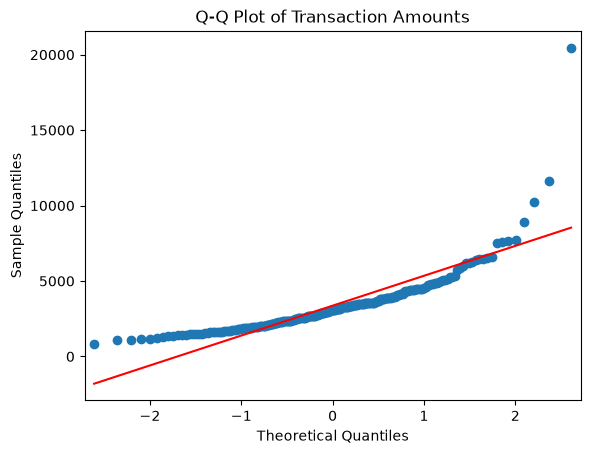

Shapiro-Wilk Statistic: 0.7360905672029521
P-value: 1.9104196066327837e-18
Data is not normally distributed.


In [11]:
# Select transaction amounts
amounts = df["transaction_amount"].dropna()

# Generate Q-Q Plot
sm.qqplot(amounts, line="s")

plt.title("Q-Q Plot of Transaction Amounts")
plt.show()

# Perform Shapiro-Wilk Test
stat, p_value = shapiro(amounts)

print("Shapiro-Wilk Statistic:", stat)
print("P-value:", p_value)

# Interpret result
if p_value < 0.05:
    print("Data is not normally distributed.")
else:
    print("Data is approximately normally distributed.")

### Observation

- Shapiro-Wilk Statistic: 0.7360905672
- P-value: 1.9104196066327837e-18
- The p-value is less than the significance level of 0.05.
- The Q-Q Plot points deviate from the straight reference line.
- The transaction amount data is not normally distributed.

### Result

The Q-Q Plot and Shapiro-Wilk test indicate that the transaction amount data is not normally distributed.

Since the p-value is less than 0.05, the null hypothesis of normality is rejected.

Therefore, the transaction amount data does not follow a normal distribution.

## Practical 5: Apply Box-Cox Transformation to Stabilize Variance

### Aim

To apply Box-Cox transformation to transaction amounts to reduce skewness and make the data more symmetric.

### Explanation

Box-Cox transformation is a statistical technique used to transform positive data into a distribution that is closer to normal.

It helps to:
- Reduce skewness.
- Stabilize variance.
- Make data more symmetric.
- Improve the normality of data.

In this project, Box-Cox transformation is applied to the `transaction_amount` column.

Skewness Before Transformation: 3.730109977696717
Lambda Value: -0.18083390743966327
Skewness After Transformation: -0.01059930647136503


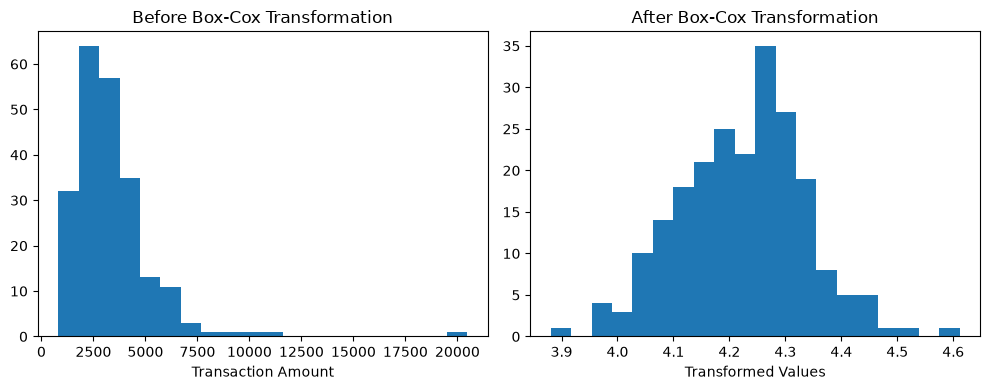

In [12]:
# Select transaction amounts
amounts = df["transaction_amount"].dropna()

# Calculate skewness before transformation
before = skew(amounts)

# Apply Box-Cox transformation
transformed, lam = boxcox(amounts)

# Calculate skewness after transformation
after = skew(transformed)

print("Skewness Before Transformation:", before)
print("Lambda Value:", lam)
print("Skewness After Transformation:", after)

# Plot comparison
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.hist(amounts, bins=20)
plt.title("Before Box-Cox Transformation")
plt.xlabel("Transaction Amount")

plt.subplot(1, 2, 2)
plt.hist(transformed, bins=20)
plt.title("After Box-Cox Transformation")
plt.xlabel("Transformed Values")

plt.tight_layout()
plt.show()

### Observation

- Skewness Before Transformation: 3.7301
- Lambda Value: -0.1808
- Skewness After Transformation: -0.0106

The original transaction amount data was highly positively skewed.

After applying Box-Cox transformation, the skewness reduced significantly and became close to zero.

The histogram after transformation shows a more symmetric distribution.

### Result

Box-Cox transformation was successfully applied to the transaction amount data.

The skewness decreased from 3.7301 to -0.0106, indicating a significant improvement in data symmetry.

Therefore, Box-Cox transformation helped make the transaction amount data more symmetric and closer to a normal distribution.

## Practical 6: Calculate Z-scores and Probability of Transactions Exceeding ₹5000

### Aim

To calculate Z-scores for transaction amounts and estimate the probability of transactions exceeding ₹5000.

### Explanation

A Z-score measures how many standard deviations a value is away from the mean.

The formula is:

Z = (X − μ) / σ

Where:

- X = Observed transaction amount.
- μ = Mean of transaction amounts.
- σ = Standard deviation.

In this project, we calculate the Z-score for ₹5000 and estimate the probability of a transaction amount exceeding ₹5000 using the normal distribution.

In [13]:
# Select transaction amounts
amounts = df["transaction_amount"].dropna()

# Calculate mean and standard deviation
mean = amounts.mean()
std = amounts.std()

# Given transaction amount
value = 5000

# Calculate Z-score
z_score = (value - mean) / std

# Calculate probability using normal distribution
probability = 1 - norm.cdf(z_score)

# Calculate actual observed proportion
actual_probability = (amounts > 5000).mean()

print("Mean:", mean)
print("Standard Deviation:", std)
print("Z-score:", z_score)
print("Normal Approximation P(X > 5000):", probability)
print("Observed Proportion Above 5000:", actual_probability)

Mean: 3365.1924090909088
Standard Deviation: 1985.705409161596
Z-score: 0.8232880785671723
Normal Approximation P(X > 5000): 0.20517209567554384
Observed Proportion Above 5000: 0.11363636363636363


### Observation

- Mean Transaction Amount: ₹3,365.19
- Standard Deviation: ₹1,985.71
- Z-score for ₹5,000: 0.8233
- Normal Approximation P(X > ₹5,000): 0.2052 (20.52%)
- Observed Proportion Above ₹5,000: 0.1136 (11.36%)

The Z-score of 0.8233 indicates that ₹5,000 is approximately 0.82 standard deviations above the mean.

The normal approximation estimates a 20.52% probability of transactions exceeding ₹5,000, while the actual observed proportion is 11.36%.

### Result

The Z-score and probability calculations were successfully performed.

The Z-score for ₹5,000 is approximately 0.8233. The normal approximation gives a probability of 20.52%, whereas the actual observed proportion is 11.36%.

Therefore, the normal approximation should be interpreted carefully because the transaction amount data is not normally distributed.

## Practical 7: Plot and Interpret PDF and CDF for Transaction Amounts

### Aim

To plot and interpret the Probability Density Function (PDF) and Cumulative Distribution Function (CDF) for transaction amounts.

### Explanation

PDF (Probability Density Function) describes the probability density of transaction amounts over a range of values.

CDF (Cumulative Distribution Function) gives the cumulative probability that a transaction amount is less than or equal to a particular value.

In this project, PDF and CDF are calculated using the fitted Log-Normal distribution of transaction amounts.

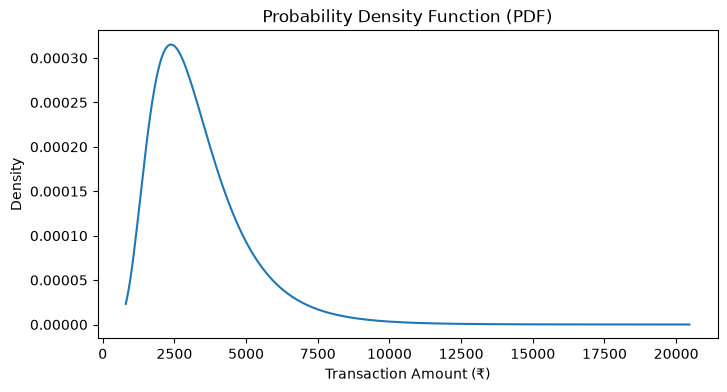

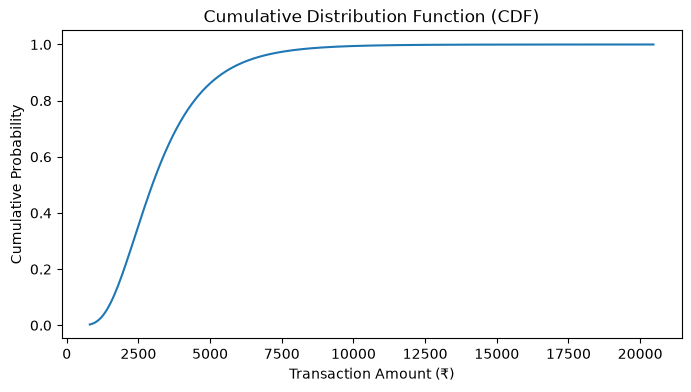

In [14]:
# Select transaction amounts
amounts = df["transaction_amount"].dropna()

# Fit Log-Normal Distribution
shape, loc, scale = lognorm.fit(
    amounts,
    floc=0
)

# Generate values for plotting
x = np.linspace(
    amounts.min(),
    amounts.max(),
    300
)

# Calculate PDF
pdf_values = lognorm.pdf(
    x,
    shape,
    loc=loc,
    scale=scale
)

# Calculate CDF
cdf_values = lognorm.cdf(
    x,
    shape,
    loc=loc,
    scale=scale
)

# Plot PDF
plt.figure(figsize=(8, 4))
plt.plot(x, pdf_values)

plt.xlabel("Transaction Amount (₹)")
plt.ylabel("Density")
plt.title("Probability Density Function (PDF)")
plt.show()

# Plot CDF
plt.figure(figsize=(8, 4))
plt.plot(x, cdf_values)

plt.xlabel("Transaction Amount (₹)")
plt.ylabel("Cumulative Probability")
plt.title("Cumulative Distribution Function (CDF)")
plt.show()

### Observation

**PDF (Probability Density Function):**

- The PDF curve is right-skewed.
- The highest density is observed around the transaction amount of ₹2,500.
- The density decreases as the transaction amount increases.
- Very high transaction amounts have lower probability density.

**CDF (Cumulative Distribution Function):**

- The CDF curve increases from 0 towards 1.
- It represents the cumulative probability of transaction amounts.
- As the transaction amount increases, the cumulative probability also increases.
- At higher transaction amounts, the cumulative probability approaches 1.

### Result

The Probability Density Function (PDF) and Cumulative Distribution Function (CDF) were successfully plotted using the fitted Log-Normal distribution.

The PDF shows the density pattern of transaction amounts, while the CDF shows the cumulative probability up to a particular transaction amount.

Therefore, PDF and CDF help us understand the distribution and probability behaviour of e-commerce transaction amounts.

## Practical 8: Conclusion – Which Distribution Best Fits the Dataset?

### Aim

To identify the best-fitting statistical distribution for the e-commerce transaction dataset and summarize the findings.

### Explanation

In this project, different statistical distributions were applied to analyze e-commerce transaction behaviour.

Bernoulli and Binomial distributions were used to study transaction outcomes and counts. Poisson distribution was used to analyze daily transactions. Log-Normal and Pareto distributions were fitted to transaction amounts.

The models were compared using statistical methods, Q-Q plots and AIC values to understand which distribution best represents the transaction amount data.

### Final Conclusion

The project analyzes e-commerce transaction data using different statistical distributions and techniques.

The main findings are:

1. The dataset contains 220 transaction records and 7 columns.
2. The average transaction amount is approximately ₹3,365.19.
3. The transaction amount data is strongly right-skewed.
4. Bernoulli distribution was used to analyze successful and failed transactions.
5. Binomial distribution was used as an exploratory approximation for transaction counts.
6. Poisson distribution was fitted to daily transaction counts.
7. Log-Normal distribution fits transaction amounts better than the fitted Pareto model based on AIC.
8. Q-Q Plot and Shapiro-Wilk test indicate that the original transaction amounts are not normally distributed.
9. Box-Cox transformation reduced skewness from 3.7301 to -0.0106.
10. Z-score analysis was used to estimate the probability of transactions exceeding ₹5,000.
11. PDF and CDF were plotted to understand transaction amount density and cumulative probability.

### Final Result

Based on the AIC comparison, the Log-Normal distribution provides a better fit than the fitted Pareto distribution for the transaction amounts in this dataset.

The analysis shows that statistical distributions and transformations are useful for understanding customer purchasing patterns, daily transaction behaviour and transaction amount probabilities.

This project helps an e-commerce business make better data-driven decisions by understanding transaction patterns.